## Importações e Configuração

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="muted")

ROOT = Path.cwd()
if not (ROOT / "data" / "sample").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "sample"
REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)

FACT_PATH = DATA_DIR / "fact_demand_pricing_daily.parquet"

## Carregamento dos Dados

In [2]:
fact = pd.read_parquet(FACT_PATH)

fact["date"] = pd.to_datetime(fact["date"])
fact = fact.sort_values(["product_id", "region_id", "date"]).reset_index(drop=True)

print(f"Linhas: {len(fact):,}")
print(f"Colunas: {fact.shape[1]}")
print(f"Período: {fact['date'].min().date()} a {fact['date'].max().date()}")

fact.head()

Linhas: 43,860
Colunas: 39
Período: 2024-01-01 a 2025-12-31


,date_id,date,year,month,quarter,week_of_year,day_of_week,is_weekend,is_holiday,holiday_name,product_id,product_name,category,abc_class,region_id,region_name,state,promo_flag,discount_pct,list_price_brl,gross_unit_price_brl,net_unit_price_brl,relative_price_index,unit_cost_brl,available_stock_units,units_sold,stockout_flag,lost_sales_estimate_units,revenue_brl,gross_margin_brl,gross_margin_pct,lag_1_units,lag_7_units,rolling_7d_units,rolling_28d_units,trend_index,anomaly_flag,anomaly_type,dataset_split
0,20240101,2024-01-01,2024,1,1,1,1,False,True,Feriado comercial,P001,Café Premium 500g,Mercearia,A,R01,Sudeste,SP,False,0.000,24.900,24.860,24.860,0.999,12.800,1,1,False,0,24.860,12.060,0.485,0,0,0.000,0.000,0.000,False,none,train
1,20240102,2024-01-02,2024,1,1,1,2,False,False,Não se aplica,P001,Café Premium 500g,Mercearia,A,R01,Sudeste,SP,False,0.000,24.900,24.800,24.800,0.996,12.800,2,1,False,0,24.800,12.000,0.484,1,0,1.000,1.000,0.003,False,none,train
2,20240103,2024-01-03,2024,1,1,1,3,False,False,Não se aplica,P001,Café Premium 500g,Mercearia,A,R01,Sudeste,SP,False,0.000,24.900,25.050,25.050,1.006,12.800,2,2,False,0,50.100,24.500,0.489,1,0,1.000,1.000,0.005,False,none,train
3,20240104,2024-01-04,2024,1,1,1,4,False,False,Não se aplica,P001,Café Premium 500g,Mercearia,A,R01,Sudeste,SP,False,0.000,24.900,25.110,25.110,1.008,12.800,1,1,False,0,25.110,12.310,0.490,2,0,1.330,1.330,0.008,False,none,train
4,20240105,2024-01-05,2024,1,1,1,5,False,False,Não se aplica,P001,Café Premium 500g,Mercearia,A,R01,Sudeste,SP,False,0.000,24.900,24.600,24.600,0.988,12.800,3,2,False,0,49.200,23.600,0.480,1,0,1.250,1.250,0.011,False,none,train


## Inspeção Estrutural e Qualidade

In [3]:
fact.info()

quality = pd.DataFrame({
    "dtype": fact.dtypes.astype(str),
    "nulls": fact.isna().sum(),
    "null_rate": fact.isna().mean(),
    "n_unique": fact.nunique(),
})

quality.sort_values("null_rate", ascending=False).head(15)

<class 'pandas.DataFrame'>
RangeIndex: 43860 entries, 0 to 43859
Data columns (total 39 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   date_id                    43860 non-null  int64         
 1   date                       43860 non-null  datetime64[us]
 2   year                       43860 non-null  int32         
 3   month                      43860 non-null  int32         
 4   quarter                    43860 non-null  int32         
 5   week_of_year               43860 non-null  int64         
 6   day_of_week                43860 non-null  int32         
 7   is_weekend                 43860 non-null  bool          
 8   is_holiday                 43860 non-null  bool          
 9   holiday_name               43860 non-null  str           
 10  product_id                 43860 non-null  str           
 11  product_name               43860 non-null  str           
 12  category       

,dtype,nulls,null_rate,n_unique
date_id,int64,0,0.000,731
date,datetime64[us],0,0.000,731
year,int32,0,0.000,2
month,int32,0,0.000,12
quarter,int32,0,0.000,4
week_of_year,int64,0,0.000,52
day_of_week,int32,0,0.000,7
is_weekend,bool,0,0.000,2
is_holiday,bool,0,0.000,2
holiday_name,str,0,0.000,2


## Verificação de Granularidade

In [4]:
key = ["date", "product_id", "region_id"]

print("Duplicidades na granularidade:", fact.duplicated(key).sum())
print("Produtos:", fact["product_id"].nunique())
print("Regiões:", fact["region_id"].nunique())
print("Categorias:", fact["category"].nunique())

Duplicidades na granularidade: 0
Produtos: 12
Regiões: 5
Categorias: 5


Regras de Consistência

In [5]:
checks = {
    "sem_nulos": fact.isna().sum().sum() == 0,
    "sem_duplicidade_na_chave": fact.duplicated(key).sum() == 0,
    "vendas_nao_negativas": (fact["units_sold"] >= 0).all(),
    "estoque_nao_negativo": (fact["available_stock_units"] >= 0).all(),
    "receita_nao_negativa": (fact["revenue_brl"] >= 0).all(),
    "receita_reconciliada": np.isclose(
        fact["revenue_brl"],
        fact["units_sold"] * fact["net_unit_price_brl"],
        atol=0.011,
    ).all(),
}

pd.Series(checks, name="pass").to_frame()

,pass
sem_nulos,True
sem_duplicidade_na_chave,True
vendas_nao_negativas,True
estoque_nao_negativo,True
receita_nao_negativa,True
receita_reconciliada,True


## Analise de Volume e Distribuição

Volume por Produto

In [6]:
volume_product = (
    fact.groupby(["product_id", "product_name", "category"], as_index=False)
    .agg(
        units_sold=("units_sold", "sum"),
        revenue_brl=("revenue_brl", "sum"),
        margin_brl=("gross_margin_brl", "sum"),
        avg_price=("net_unit_price_brl", "mean"),
        stockout_rate=("stockout_flag", "mean"),
    )
    .sort_values("units_sold", ascending=False)
)

volume_product.head(10)

,product_id,product_name,category,units_sold,revenue_brl,margin_brl,avg_price,stockout_rate
1,P002,Café Tradicional 500g,Mercearia,6471,"107,115.610","54,427.620",16.690,0.108
5,P006,Sabonete Líquido 250ml,Higiene,4597,"58,085.580","33,102.830",12.742,0.033
0,P001,Café Premium 500g,Mercearia,4548,"110,862.070","50,440.340",24.599,0.066
7,P008,Lenço Umedecido 48un,Bebês,4413,"51,460.390","28,801.330",11.763,0.073
3,P004,Arroz Tipo 1 5kg,Mercearia,3578,"111,608.480","45,333.830",31.482,0.023
11,P012,Carregador USB-C,Eletrônicos,3353,"130,810.740","66,750.720",39.407,0.024
4,P005,Shampoo Hidratante 400ml,Higiene,2706,"57,989.070","29,251.960",21.648,0.010
9,P010,Areia Higiênica 4kg,Pet,1841,"51,690.910","21,809.800",28.512,0.008
6,P007,Fralda Infantil M 30un,Bebês,1677,"79,866.010","31,521.560",48.293,0.009
2,P003,Azeite Extra Virgem 500ml,Mercearia,1291,"49,997.290","21,888.110",39.395,0.005


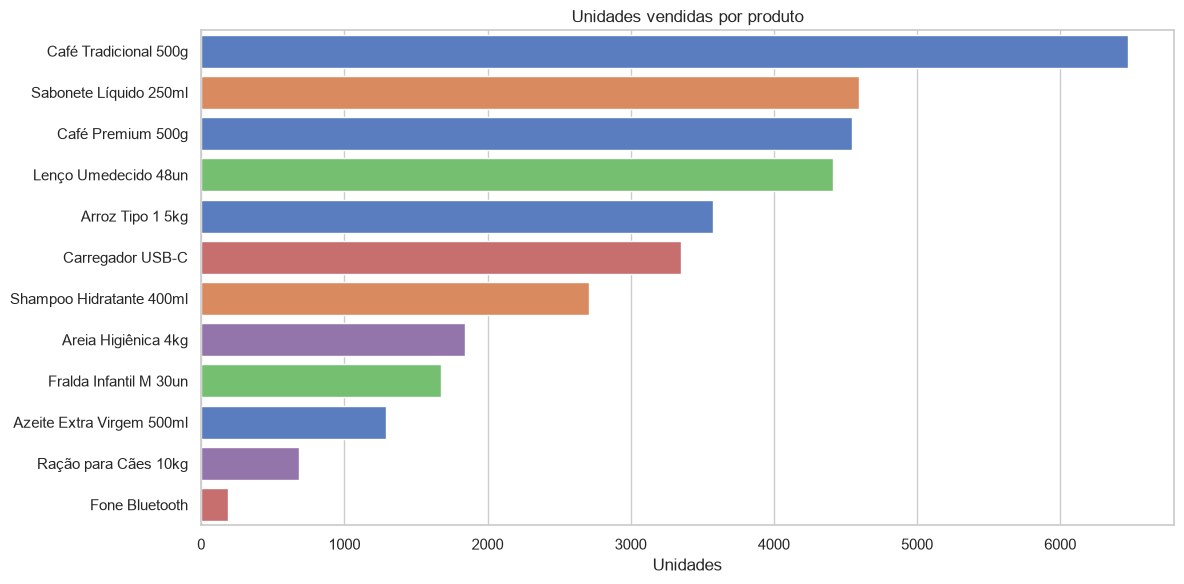

In [7]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=volume_product,
    y="product_name",
    x="units_sold",
    hue="category",
    dodge=False,
    legend=False,
)
plt.title("Unidades vendidas por produto")
plt.xlabel("Unidades")
plt.ylabel("")
plt.tight_layout()
plt.show()

Distribuição das Vendas Diárias

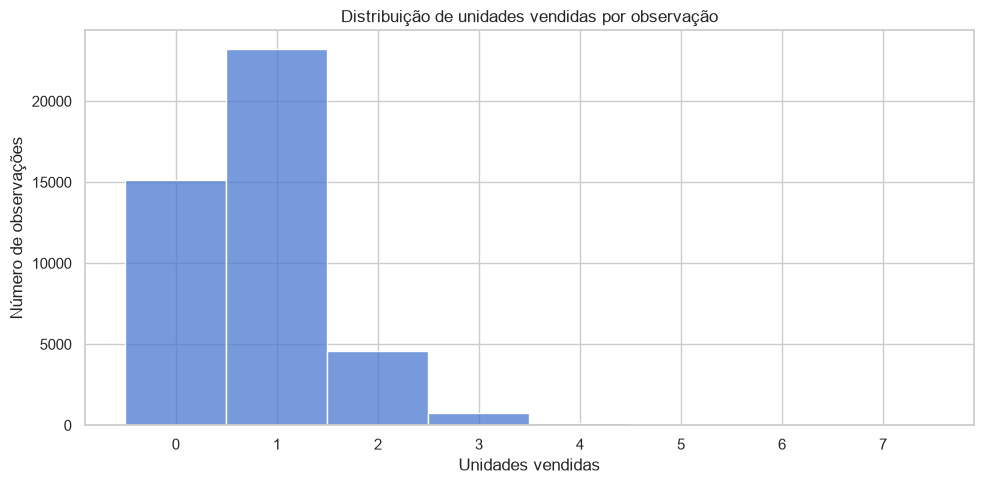

In [8]:
plt.figure(figsize=(10, 5))
sns.histplot(data=fact, x="units_sold", discrete=True, bins=30)
plt.title("Distribuição de unidades vendidas por observação")
plt.xlabel("Unidades vendidas")
plt.ylabel("Número de observações")
plt.tight_layout()
plt.show()

# Sazonalidade

Serie Temporal Agregada


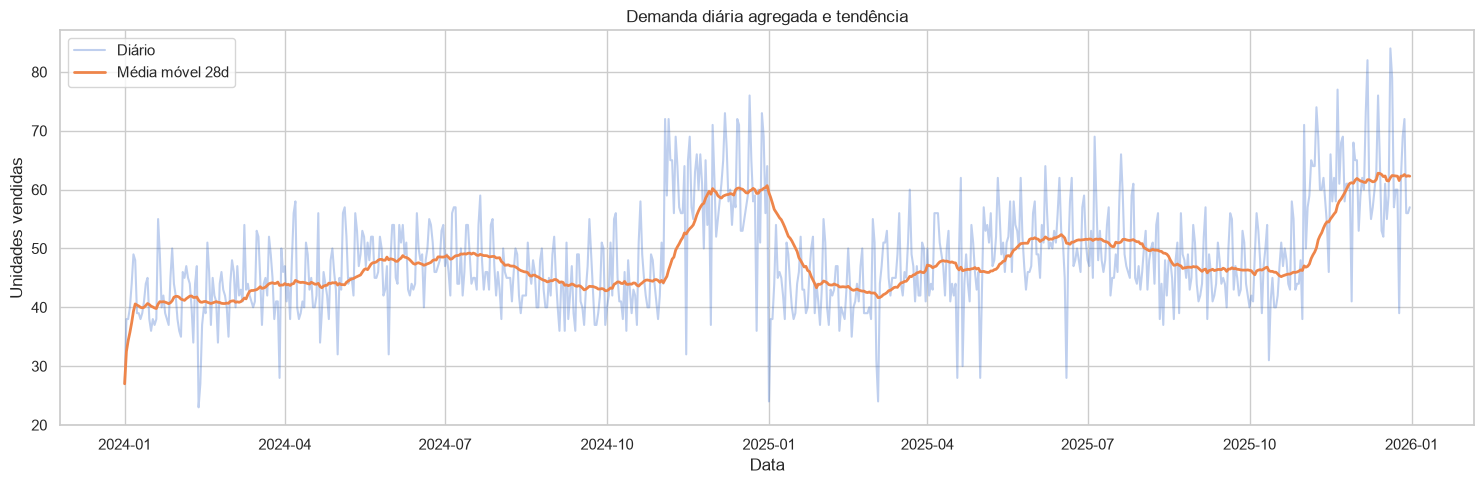

In [9]:
daily = (
    fact.groupby("date", as_index=False)
    .agg(
        units_sold=("units_sold", "sum"),
        revenue_brl=("revenue_brl", "sum"),
        margin_brl=("gross_margin_brl", "sum"),
        stockout_rate=("stockout_flag", "mean"),
    )
)

daily["rolling_28d"] = daily["units_sold"].rolling(28, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily["date"], daily["units_sold"], alpha=0.35, label="Diário")
ax.plot(daily["date"], daily["rolling_28d"], linewidth=2, label="Média móvel 28d")
ax.set_title("Demanda diária agregada e tendência")
ax.set_xlabel("Data")
ax.set_ylabel("Unidades vendidas")
ax.legend()
plt.tight_layout()
plt.show()

Sazonalidade por Mês e Trimestre

In [10]:
seasonality = (
    fact.groupby(["month", "quarter"], as_index=False)
    .agg(
        mean_units=("units_sold", "mean"),
        total_units=("units_sold", "sum"),
        mean_revenue=("revenue_brl", "mean"),
        stockout_rate=("stockout_flag", "mean"),
    )
)

seasonality

,month,quarter,mean_units,total_units,mean_revenue,stockout_rate
0,1,1,0.701,2609,17.229,0.027
1,2,1,0.691,2363,17.157,0.030
2,3,1,0.752,2796,19.020,0.025
3,4,2,0.757,2724,18.992,0.030
4,5,2,0.819,3045,21.051,0.031
5,6,2,0.838,3018,21.762,0.029
6,7,3,0.824,3067,20.999,0.029
7,8,3,0.763,2838,19.121,0.026
8,9,3,0.744,2679,18.559,0.033
9,10,4,0.750,2790,18.935,0.033


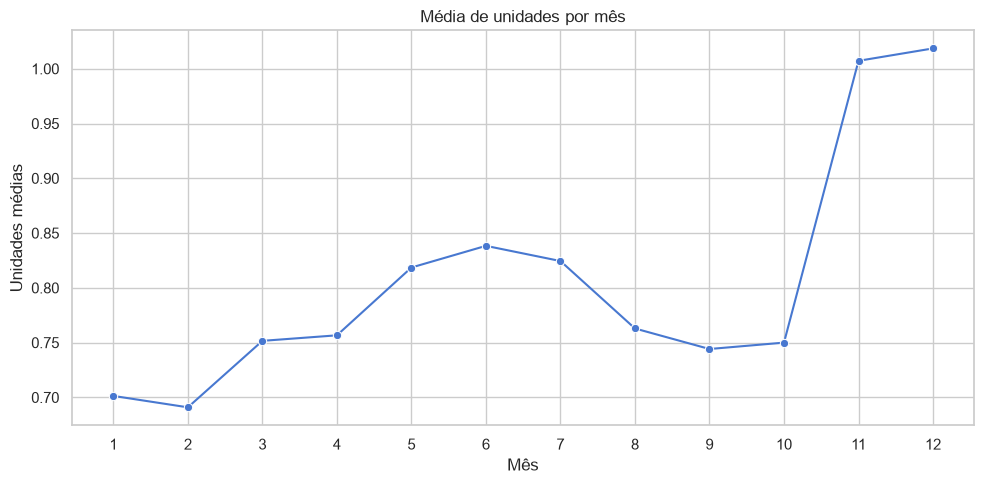

In [11]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=seasonality, x="month", y="mean_units", marker="o")
plt.title("Média de unidades por mês")
plt.xlabel("Mês")
plt.ylabel("Unidades médias")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

Finais de Semana, Feriados e Promos

In [12]:
calendar_effects = (
    fact.groupby(["is_weekend", "is_holiday", "promo_flag"], as_index=False)
    .agg(
        mean_units=("units_sold", "mean"),
        median_units=("units_sold", "median"),
        observations=("units_sold", "size"),
    )
)

calendar_effects

,is_weekend,is_holiday,promo_flag,mean_units,median_units,observations
0,False,False,False,0.740,1.000,28383
1,False,False,True,1.261,1.000,1917
2,False,True,False,0.479,0.000,1002
3,False,True,True,0.859,1.000,78
4,True,False,False,0.876,1.000,10929
5,True,False,True,1.386,1.000,1071
6,True,True,False,0.618,1.000,432
7,True,True,True,1.000,1.000,48


Comparação Simples de Promoção

In [13]:
promo_summary = fact.groupby("promo_flag").agg(
    mean_units=("units_sold", "mean"),
    median_units=("units_sold", "median"),
    mean_discount=("discount_pct", "mean"),
    mean_revenue=("revenue_brl", "mean"),
)

promo_summary

,mean_units,median_units,mean_discount,mean_revenue
promo_flag,,,,
False,0.769,1.000,0.000,19.924
True,1.290,1.000,0.177,29.420


# Outliers e Anomalias

A base tem anomalias explicitas para demonstração de qualidade e modelagem

In [14]:
fact["anomaly_type"].value_counts(dropna=False)

anomaly_type
none                     43319
demand_spike               307
price_error                142
inventory_count_error       92
Name: count, dtype: int64

Outliers por IQR

In [15]:
def iqr_bounds(series: pd.Series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

low, high = iqr_bounds(fact["units_sold"])
fact["units_outlier_iqr"] = (fact["units_sold"] < low) | (fact["units_sold"] > high)

print("Limite inferior:", low)
print("Limite superior:", high)
print("Outliers IQR:", fact["units_outlier_iqr"].sum())

Limite inferior: -1.5
Limite superior: 2.5
Outliers IQR: 915


Outliers por Produto-Região

In [16]:
group_cols = ["product_id", "region_id"]

g = fact.groupby(group_cols)["units_sold"]
q1 = g.transform(lambda s: s.quantile(0.25))
q3 = g.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

fact["units_outlier_group"] = (
    (fact["units_sold"] < q1 - 1.5 * iqr) |
    (fact["units_sold"] > q3 + 1.5 * iqr)
)

outlier_review = fact.loc[
    fact["units_outlier_group"] | fact["anomaly_flag"],
    ["date", "product_id", "region_id", "units_sold", "promo_flag", "stockout_flag", "anomaly_type"]
].sort_values("units_sold", ascending=False)

outlier_review.head(20)

,date,product_id,region_id,units_sold,promo_flag,stockout_flag,anomaly_type
4361,2025-12-07,P002,R01,7,True,False,none
4374,2025-12-20,P002,R01,7,True,False,none
4009,2024-12-20,P002,R01,6,True,False,none
4536,2024-05-30,P002,R02,6,True,False,none
4333,2025-11-09,P002,R01,6,True,False,none
2504,2024-11-07,P001,R04,6,True,False,none
2181,2025-12-20,P001,R03,6,True,False,none
4168,2025-05-28,P002,R01,6,True,False,none
5765,2025-10-10,P002,R03,6,True,False,none
26634,2024-11-14,P008,R02,6,True,True,none


Decisão analítica

In [ ]:
model_data_raw = fact.copy()
model_data_without_known_anomalies = fact.loc[~fact["anomaly_flag"]].copy()

# Analise de Rupturas

Taxa de Ruptura por Produto e Região

In [17]:
stockout_product_region = (
    fact.groupby(["product_id", "product_name", "region_name"], as_index=False)
    .agg(
        stockout_rate=("stockout_flag", "mean"),
        lost_sales_units=("lost_sales_estimate_units", "sum"),
        units_sold=("units_sold", "sum"),
        revenue_brl=("revenue_brl", "sum"),
    )
    .sort_values("stockout_rate", ascending=False)
)

stockout_product_region.head(15)

,product_id,product_name,region_name,stockout_rate,lost_sales_units,units_sold,revenue_brl
8,P002,Café Tradicional 500g,Sudeste,0.145,129,1945,"32,274.090"
6,P002,Café Tradicional 500g,Nordeste,0.119,102,1312,"21,675.850"
5,P002,Café Tradicional 500g,Centro-Oeste,0.111,84,1015,"16,797.050"
9,P002,Café Tradicional 500g,Sul,0.105,92,1430,"23,705.390"
38,P008,Lenço Umedecido 48un,Sudeste,0.105,81,1302,"15,226.980"
3,P001,Café Premium 500g,Sudeste,0.100,83,1347,"32,850.010"
39,P008,Lenço Umedecido 48un,Sul,0.100,80,911,"10,546.180"
4,P001,Café Premium 500g,Sul,0.088,68,948,"23,120.320"
1,P001,Café Premium 500g,Nordeste,0.082,61,845,"20,499.750"
36,P008,Lenço Umedecido 48un,Nordeste,0.079,60,822,"9,562.190"


Relação entre estoque e vendas

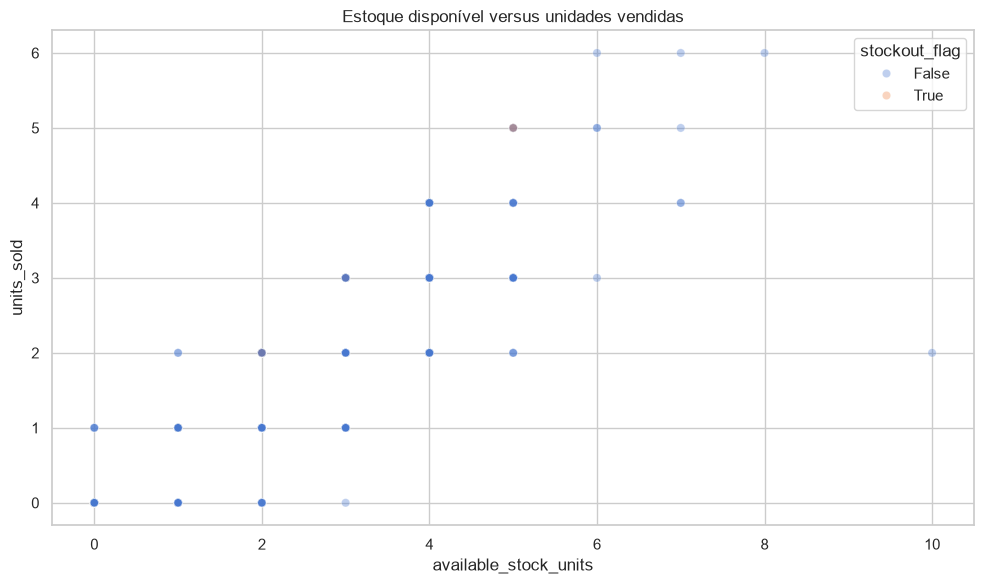

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=fact.sample(min(10000, len(fact)), random_state=42),
    x="available_stock_units",
    y="units_sold",
    hue="stockout_flag",
    alpha=0.35,
)
plt.title("Estoque disponível versus unidades vendidas")
plt.tight_layout()
plt.show()

# Separação Temporal Correta

In [19]:
split_summary = fact.groupby("dataset_split").agg(
    min_date=("date", "min"),
    max_date=("date", "max"),
    rows=("date", "size"),
)

split_summary

,min_date,max_date,rows
dataset_split,,,
test,2025-07-01,2025-12-31,11040
train,2024-01-01,2024-12-31,21960
validation,2025-01-01,2025-06-30,10860


In [20]:
assert split_summary.loc["train", "max_date"] < split_summary.loc["validation", "min_date"]
assert split_summary.loc["validation", "max_date"] < split_summary.loc["test", "min_date"]

# Baseline Ingênuo

In [21]:
baseline = fact.copy()
baseline = baseline.sort_values(["product_id", "region_id", "date"])

baseline["prediction_naive_1d"] = (
    baseline.groupby(["product_id", "region_id"])["units_sold"]
    .shift(1)
    .fillna(0)
)

In [22]:
baseline["prediction_seasonal_7d"] = (
    baseline.groupby(["product_id", "region_id"])["units_sold"]
    .shift(7)
    .fillna(0)
)

# Métricas WAPE, MAE e RMSE

In [23]:
def wape(y_true, y_pred):
    denominator = np.abs(y_true).sum()
    if denominator == 0:
        return np.nan
    return np.abs(y_true - y_pred).sum() / denominator


def evaluate(data, target_col, prediction_col):
    y_true = data[target_col].to_numpy()
    y_pred = data[prediction_col].to_numpy()
    return pd.Series({
        "WAPE": wape(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "observations": len(data),
    })

In [24]:
test = baseline.loc[baseline["dataset_split"] == "test"].copy()

overall_metrics = pd.DataFrame({
    "naive_1d": evaluate(test, "units_sold", "prediction_naive_1d"),
    "seasonal_7d": evaluate(test, "units_sold", "prediction_seasonal_7d"),
}).T

overall_metrics

,WAPE,MAE,RMSE,observations
naive_1d,0.357,0.311,0.604,"11,040.000"
seasonal_7d,0.350,0.305,0.598,"11,040.000"


Métricas por produto e região

In [25]:
def evaluate_group(group):
    result = evaluate(group, "units_sold", "prediction_seasonal_7d")
    return result

metrics_product_region = (
    test.groupby(["product_id", "region_id"], group_keys=True)
    .apply(evaluate_group, include_groups=False)
    .reset_index()
)

metrics_product_region.sort_values("WAPE", ascending=False).head(15)

,product_id,region_id,WAPE,MAE,RMSE,observations
43,P009,R04,2.167,0.071,0.266,184.000
51,P011,R02,2.000,0.130,0.361,184.000
14,P003,R05,2.000,0.043,0.209,184.000
53,P011,R04,2.000,0.011,0.104,184.000
44,P009,R05,2.000,0.011,0.104,184.000
34,P007,R05,1.875,0.082,0.286,184.000
52,P011,R03,1.857,0.071,0.266,184.000
42,P009,R03,1.531,0.266,0.516,184.000
50,P011,R01,1.405,0.321,0.585,184.000
49,P010,R05,1.385,0.098,0.313,184.000


# Curva Real vs Baseline

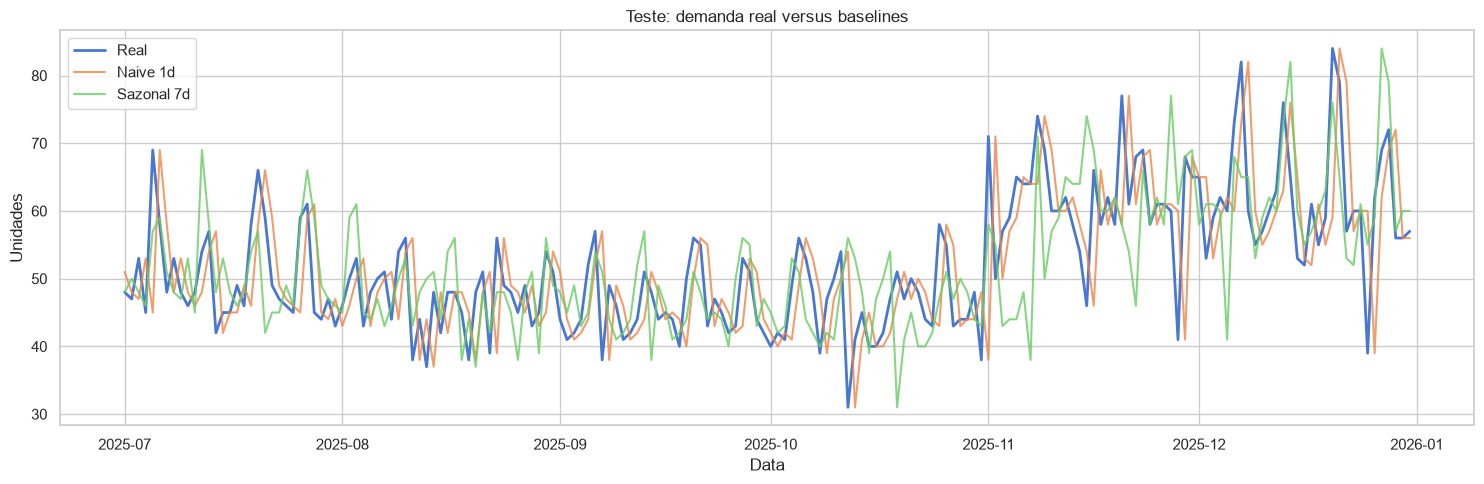

In [26]:
series = (
    test.groupby("date", as_index=False)
    .agg(
        actual=("units_sold", "sum"),
        naive_1d=("prediction_naive_1d", "sum"),
        seasonal_7d=("prediction_seasonal_7d", "sum"),
    )
)

plt.figure(figsize=(15, 5))
plt.plot(series["date"], series["actual"], label="Real", linewidth=2)
plt.plot(series["date"], series["naive_1d"], label="Naive 1d", alpha=0.8)
plt.plot(series["date"], series["seasonal_7d"], label="Sazonal 7d", alpha=0.8)
plt.title("Teste: demanda real versus baselines")
plt.xlabel("Data")
plt.ylabel("Unidades")
plt.legend()
plt.tight_layout()
plt.show()

# Exportar resultados da Trilha A

In [27]:
REPORT_DIR.mkdir(exist_ok=True)

volume_product.to_csv(REPORT_DIR / "trilha_a_volume_por_produto.csv", index=False)
seasonality.to_csv(REPORT_DIR / "trilha_a_sazonalidade.csv", index=False)
stockout_product_region.to_csv(REPORT_DIR / "trilha_a_rupturas.csv", index=False)
metrics_product_region.to_csv(REPORT_DIR / "trilha_a_metricas_por_produto_regiao.csv", index=False)
overall_metrics.to_csv(REPORT_DIR / "trilha_a_metricas_baseline.csv")

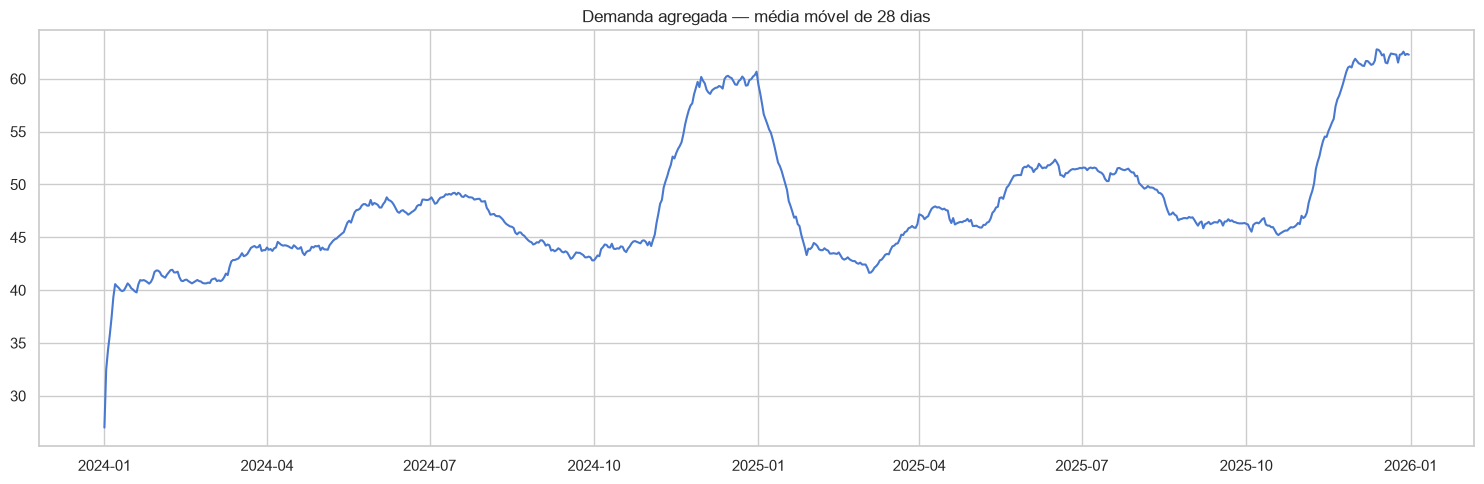

In [28]:
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.figure(figsize=(15, 5))
plt.plot(daily["date"], daily["rolling_28d"])
plt.title("Demanda agregada — média móvel de 28 dias")
plt.tight_layout()
plt.savefig(FIG_DIR / "demanda_rolling_28d.png", dpi=160, bbox_inches="tight")
plt.show()